In [ ]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, KFold
from sklearn.preprocessing import LabelEncoder
from collections import Counter
import requests

RANDOM_SEED = 0
np.random.seed(RANDOM_SEED)

In [ ]:
# ---------------------- Utilities ----------------------

def add_intercept(X):
    """
    Return X with a leading column of ones (bias term).
    Ensure float dtype; do not modify X in-place.
    """
    X = np.asarray(X, dtype=float)
    ones = np.ones((X.shape[0], 1), dtype=float)
    return np.hstack([ones, X])


def standardize_fit(X_train, eps=1e-12):
    X = np.asarray(X_train, dtype=float)
    mean = X.mean(axis=0)
    std = X.std(axis=0)
    std = np.maximum(std, eps)
    Xs = (X - mean) / std
    return Xs, mean, std


def standardize_apply(X, mean, std, eps=1e-12):
    X = np.asarray(X, dtype=float)
    std = np.maximum(std, eps)
    return (X - mean) / std


def train_test_split_idx(n, test_size, seed=0):
    rng = np.random.RandomState(seed)
    idx = np.arange(n)
    rng.shuffle(idx)
    t = int(np.floor((1 - test_size) * n))
    train_idx = np.sort(idx[:t])
    test_idx = np.sort(idx[t:])
    return train_idx, test_idx



In [ ]:
# ---------------------- Linear Regression ----------------------

def mse(y, yhat):
    y = np.asarray(y).ravel()
    yhat = np.asarray(yhat).ravel()
    return np.mean((y - yhat) ** 2)


def r2_score(y, yhat):
    y = np.asarray(y).ravel()
    yhat = np.asarray(yhat).ravel()
    ss_res = np.sum((y - yhat) ** 2)
    ss_tot = np.sum((y - y.mean()) ** 2)
    if ss_tot == 0:
        return 1.0 if ss_res == 0 else 0.0
    return 1 - ss_res / ss_tot


def fit_linear_closed_form(X, y, add_bias=True, rcond=None):
    X = np.asarray(X, dtype=float)
    y = np.asarray(y, dtype=float).ravel()
    if add_bias:
        Xp = add_intercept(X)
    else:
        Xp = X
    # prefer pinv
    w = np.linalg.pinv(Xp) @ y
    return w


def fit_linear_gd(X, y, lr=0.05, iters=5000, add_bias=True):
    X = np.asarray(X, dtype=float)
    y = np.asarray(y, dtype=float).ravel()
    if add_bias:
        Xp = add_intercept(X)
    else:
        Xp = X
    n, p = Xp.shape
    w = np.zeros(p, dtype=float)
    losses = []
    for it in range(iters):
        yhat = Xp @ w
        grad = (-2.0 / n) * (Xp.T @ (y - yhat))
        w = w - lr * grad
        if it % max(1, iters // 200) == 0:
            losses.append(mse(y, yhat))
    return w, losses
    '''
def fit_linear_gd(X, y, lr=0.05, iters=5000, add_bias=True):
  X = np.asarray(X, dtype=float)
  y = np.asarray(y).ravel()
  if add_bias:
       Xp = add_intercept(X)
  else:
    Xp = X
  n, p = Xp.shape
  w = np.zeros(p, dtype=float)
  losses = []
  its = []
  for it in range(iters):
        yhat = Xp @ w
        grad = (-2.0 / n) * (Xp.T @ (y - yhat))
        w = w - lr * grad
        if it % 50 == 0:   # record every 50 iterations
            losses.append(mse(y, yhat))
            its.append(it)
  return w, its, losses'''



def predict_linear(X, w, has_bias=True):
    X = np.asarray(X, dtype=float)
    if has_bias:
        Xp = add_intercept(X)
    else:
        Xp = X
    yhat = Xp @ w
    return yhat.ravel()


In [ ]:
# ---------------------- Logistic Regression ----------------------

def sigmoid(z):
    z = np.asarray(z)
    # numerically stable sigmoid
    out = np.empty_like(z, dtype=float)
    pos = z >= 0
    neg = ~pos
    out[pos] = 1.0 / (1.0 + np.exp(-z[pos]))
    exp_z = np.exp(z[neg])
    out[neg] = exp_z / (1.0 + exp_z)
    return out


def logreg_nll(X, y, w, lam=0.0):
    X = np.asarray(X, dtype=float)
    y = np.asarray(y).ravel()
    if X.shape[1] == w.shape[0] - 1:
        Xp = add_intercept(X)
    else:
        Xp = X
    logits = Xp @ w
    p = sigmoid(logits)
    eps = 1e-12
    nll = -np.sum(y * np.log(p + eps) + (1 - y) * np.log(1 - p + eps))
    # regularize excluding intercept
    if w.shape[0] > 0:
        nll += 0.5 * lam * np.sum(w[1:] ** 2)
    return nll


def fit_logreg_gd(X, y, lam=0.0, lr=0.1, iters=5000, add_bias=True):
    X = np.asarray(X, dtype=float)
    y = np.asarray(y).ravel()
    if add_bias:
        Xp = add_intercept(X)
    else:
        Xp = X
    n, p = Xp.shape
    w = np.zeros(p, dtype=float)
    losses = []
    for it in range(iters):
        logits = Xp @ w
        p_hat = sigmoid(logits)
        grad = - (Xp.T @ (y - p_hat))
        # add L2 for non-intercept
        grad[1:] += lam * w[1:]
        w = w - lr * grad / n
        if it % max(1, iters // 200) == 0:
            losses.append(logreg_nll(X, y, w, lam=lam))
    return w, losses


def fit_logreg_newton(X, y, lam=0.0, iters=100, tol=1e-6, add_bias=True, damping=1e-6):
    X = np.asarray(X, dtype=float)
    y = np.asarray(y).ravel()
    if add_bias:
        Xp = add_intercept(X)
    else:
        Xp = X
    n, p = Xp.shape
    w = np.zeros(p, dtype=float)
    losses = []
    for it in range(iters):
        logits = Xp @ w
        p_hat = sigmoid(logits)
        grad = - (Xp.T @ (y - p_hat)) + np.concatenate([[0.0], lam * w[1:]])
        # Hessian
        S = p_hat * (1 - p_hat)
        # Build H = X^T S X + diag(reg)
        # compute X^T (S[:,None] * X)
        XS = Xp * S[:, None]
        H = XS.T @ Xp
        # regularize non-intercept
        reg = np.zeros((p, p))
        reg[1:, 1:] = lam * np.eye(p - 1)
        H += reg
        # damping
        H += damping * np.eye(p)
        # solve for delta
        try:
            delta = np.linalg.solve(H, grad)
        except np.linalg.LinAlgError:
            delta = np.linalg.pinv(H) @ grad
        w_new = w - delta
        losses.append(logreg_nll(X, y, w_new, lam=lam))
        if np.linalg.norm(w_new - w) < tol:
            w = w_new
            break
        w = w_new
    return w, losses


def predict_proba_logreg(X, w, has_bias=True):
    X = np.asarray(X, dtype=float)
    if has_bias:
        Xp = add_intercept(X)
    else:
        Xp = X
    logits = Xp @ w
    return sigmoid(logits)


def predict_logreg(X, w, threshold=0.5, has_bias=True):
    p = predict_proba_logreg(X, w, has_bias=has_bias)
    return (p >= threshold).astype(int)


In [ ]:
# ---------------------- Decision Trees ----------------------

class DTNode:
    def __init__(self, feature=None, threshold=None, left=None, right=None, *, value=None, is_leaf=False):
        self.feature = feature
        self.threshold = threshold
        self.left = left
        self.right = right
        self.value = value
        self.is_leaf = is_leaf


def entropy(y):
    y = np.asarray(y)
    if y.size == 0:
        return 0.0
    counts = np.bincount(y.astype(int))
    probs = counts[counts > 0] / y.size
    return -np.sum(probs * np.log2(probs))


def gini(y):
    y = np.asarray(y)
    if y.size == 0:
        return 0.0
    counts = np.bincount(y.astype(int))
    probs = counts / y.size
    return 1.0 - np.sum(probs ** 2)


def mse_impurity(y):
    y = np.asarray(y, dtype=float)
    if y.size == 0:
        return 0.0
    return np.mean((y - y.mean()) ** 2)


def best_split(X, y, criterion="gini", min_samples_leaf=1):
    n, p = X.shape
    best_feat = None
    best_thr = None
    best_gain = 0.0
    if criterion == "gini":
        parent_imp = gini(y)
        impurity_fn = gini
    elif criterion == "entropy":
        parent_imp = entropy(y)
        impurity_fn = entropy
    elif criterion == "mse":
        parent_imp = mse_impurity(y)
        impurity_fn = mse_impurity
    else:
        raise ValueError("Unknown criterion")
    for feat in range(p):
        vals = X[:, feat]
        sorted_idx = np.argsort(vals)
        vals_sorted = vals[sorted_idx]
        y_sorted = y[sorted_idx]
        # consider thresholds between unique consecutive values
        for i in range(1, n):
            if vals_sorted[i] == vals_sorted[i - 1]:
                continue
            left_count = i
            right_count = n - i
            if left_count < min_samples_leaf or right_count < min_samples_leaf:
                continue
            thr = 0.5 * (vals_sorted[i] + vals_sorted[i - 1])
            y_left = y_sorted[:i]
            y_right = y_sorted[i:]
            imp_left = impurity_fn(y_left)
            imp_right = impurity_fn(y_right)
            weighted = (left_count / n) * imp_left + (right_count / n) * imp_right
            gain = parent_imp - weighted
            if gain > best_gain:
                best_gain = gain
                best_feat = feat
                best_thr = thr
    return best_feat, best_thr, best_gain


def build_tree_classifier(X, y, max_depth=None, min_samples_split=2,
                          min_samples_leaf=1, criterion="gini", depth=0):
    y = np.asarray(y)
    n = y.size
    # stop conditions
    if n < min_samples_split or (max_depth is not None and depth >= max_depth) or np.unique(y).size == 1:
        # leaf
        counts = Counter(y.tolist())
        value = max(counts.items(), key=lambda kv: kv[1])[0]
        return DTNode(value=value, is_leaf=True)
    feat, thr, gain = best_split(X, y, criterion=criterion, min_samples_leaf=min_samples_leaf)
    if feat is None or gain <= 0:
        counts = Counter(y.tolist())
        value = max(counts.items(), key=lambda kv: kv[1])[0]
        return DTNode(value=value, is_leaf=True)
    mask_left = X[:, feat] <= thr
    left = build_tree_classifier(X[mask_left], y[mask_left], max_depth=max_depth,
                                 min_samples_split=min_samples_split, min_samples_leaf=min_samples_leaf,
                                 criterion=criterion, depth=depth + 1)
    right = build_tree_classifier(X[~mask_left], y[~mask_left], max_depth=max_depth,
                                  min_samples_split=min_samples_split, min_samples_leaf=min_samples_leaf,
                                  criterion=criterion, depth=depth + 1)
    return DTNode(feature=feat, threshold=thr, left=left, right=right, is_leaf=False)


def build_tree_regressor(X, y, max_depth=None, min_samples_split=2,
                         min_samples_leaf=1, depth=0):
    y = np.asarray(y, dtype=float)
    n = y.size
    if n < min_samples_split or (max_depth is not None and depth >= max_depth) or n == 0:
        return DTNode(value=float(np.mean(y)) if n > 0 else 0.0, is_leaf=True)
    feat, thr, gain = best_split(X, y, criterion="mse", min_samples_leaf=min_samples_leaf)
    if feat is None or gain <= 0:
        return DTNode(value=float(np.mean(y)), is_leaf=True)
    mask_left = X[:, feat] <= thr
    left = build_tree_regressor(X[mask_left], y[mask_left], max_depth=max_depth,
                                min_samples_split=min_samples_split, min_samples_leaf=min_samples_leaf,
                                depth=depth + 1)
    right = build_tree_regressor(X[~mask_left], y[~mask_left], max_depth=max_depth,
                                 min_samples_split=min_samples_split, min_samples_leaf=min_samples_leaf,
                                 depth=depth + 1)
    return DTNode(feature=feat, threshold=thr, left=left, right=right, is_leaf=False)


def _predict_one_tree(x, node):
    if node.is_leaf:
        return node.value
    if x[node.feature] <= node.threshold:
        return _predict_one_tree(x, node.left)
    else:
        return _predict_one_tree(x, node.right)


def predict_tree(X, tree):
    X = np.asarray(X, dtype=float)
    preds = np.array([_predict_one_tree(x, tree) for x in X])
    return preds

# ---------------------- Helper metrics (manual) ----------------------

def accuracy(y, yhat):
    return np.mean(y == yhat)


def precision_recall_f1(y, yhat):
    tp = np.sum((y == 1) & (yhat == 1))
    fp = np.sum((y == 0) & (yhat == 1))
    fn = np.sum((y == 1) & (yhat == 0))
    prec = tp / (tp + fp) if (tp + fp) > 0 else 0.0
    rec = tp / (tp + fn) if (tp + fn) > 0 else 0.0
    f1 = 2 * prec * rec / (prec + rec) if (prec + rec) > 0 else 0.0
    return prec, rec, f1


def confusion_matrix(y, yhat):
    classes = np.unique(np.concatenate([y, yhat]))
    classes.sort()
    m = np.zeros((classes.size, classes.size), dtype=int)
    for i, a in enumerate(classes):
        for j, b in enumerate(classes):
            m[i, j] = np.sum((y == a) & (yhat == b))
    return classes, m



In [ ]:
# ---------------------- Data loading & EDA ----------------------

DATA_DIR = './data'
os.makedirs(DATA_DIR, exist_ok=True)

wine_url = 'https://archive.ics.uci.edu/ml/machine-learning-databases/wine-quality/winequality-red.csv'
bank_url = 'https://archive.ics.uci.edu/ml/machine-learning-databases/00267/data_banknote_authentication.txt'
iris_url = 'https://archive.ics.uci.edu/ml/machine-learning-databases/iris/iris.data'

wine_path = os.path.join(DATA_DIR, 'winequality-red.csv')
bank_path = os.path.join(DATA_DIR, 'data_banknote_authentication.txt')
iris_path = os.path.join(DATA_DIR, 'iris.data')

if not os.path.exists(wine_path):
    try:
        response = requests.get(wine_url)
        response.raise_for_status()  # Raise an exception for bad status codes
        with open(wine_path, 'w') as f:
            f.write(response.text)
        df_wine = pd.read_csv(wine_path, sep=';')
    except Exception as e:
        print('Failed to download wine dataset, please place it in ./data or check URL')
        raise
else:
    df_wine = pd.read_csv(wine_path, sep=';')

if not os.path.exists(bank_path):
    try:
        response = requests.get(bank_url)
        response.raise_for_status()
        with open(bank_path, 'w') as f:
            f.write(response.text)
        df_bank = pd.read_csv(bank_path, header=None, sep=',')
    except Exception as e:
        print('Failed to download bank dataset, please place it in ./data or check URL')
        raise
else:
    df_bank = pd.read_csv(bank_path, header=None, sep=',')


if not os.path.exists(iris_path):
    try:
        response = requests.get(iris_url)
        response.raise_for_status()
        with open(iris_path, 'w') as f:
            f.write(response.text)
        df_iris = pd.read_csv(iris_path, header=None)
    except Exception as e:
        print('Failed to download iris dataset, please place it in ./data or check URL')
        raise
else:
    df_iris = pd.read_csv(iris_path, header=None)


In [ ]:
# Inspect and clean
print('\nWine shape:', df_wine.shape)
print(df_wine.head())
print('\nBank shape:', df_bank.shape)
print(df_bank.head())
print('\nIris shape:', df_iris.shape)
print(df_iris.head())



Wine shape: (1599, 12)
   fixed acidity  volatile acidity  citric acid  residual sugar  chlorides  \
0            7.4              0.70         0.00             1.9      0.076   
1            7.8              0.88         0.00             2.6      0.098   
2            7.8              0.76         0.04             2.3      0.092   
3           11.2              0.28         0.56             1.9      0.075   
4            7.4              0.70         0.00             1.9      0.076   

   free sulfur dioxide  total sulfur dioxide  density    pH  sulphates  \
0                 11.0                  34.0   0.9978  3.51       0.56   
1                 25.0                  67.0   0.9968  3.20       0.68   
2                 15.0                  54.0   0.9970  3.26       0.65   
3                 17.0                  60.0   0.9980  3.16       0.58   
4                 11.0                  34.0   0.9978  3.51       0.56   

   alcohol  quality  
0      9.4        5  
1      9.8        

In [ ]:
# Assign column names
# Wine already has header
# Banknote has 5 columns: 4 features + class
if df_bank.shape[1] == 5:
    df_bank.columns = ['variance', 'skewness', 'curtosis', 'entropy', 'class']
else:
    df_bank.columns = [0,1,2,3,4]

# Iris: last column is species
if df_iris.shape[1] == 5:
    df_iris.columns = ['sepal_len','sepal_wid','petal_len','petal_wid','species']



In [ ]:
# Basic stats
print('\nWine numeric stats:')
print(df_wine.describe().T[['mean','50%','std','min','max']])
print('\nBank numeric stats:')
print(df_bank.describe().T[['mean','50%','std','min','max']])
print('\nIris numeric stats:')
print(df_iris.describe().T[['mean','50%','std','min','max']])



Wine numeric stats:
                           mean       50%        std      min        max
fixed acidity          8.319637   7.90000   1.741096  4.60000   15.90000
volatile acidity       0.527821   0.52000   0.179060  0.12000    1.58000
citric acid            0.270976   0.26000   0.194801  0.00000    1.00000
residual sugar         2.538806   2.20000   1.409928  0.90000   15.50000
chlorides              0.087467   0.07900   0.047065  0.01200    0.61100
free sulfur dioxide   15.874922  14.00000  10.460157  1.00000   72.00000
total sulfur dioxide  46.467792  38.00000  32.895324  6.00000  289.00000
density                0.996747   0.99675   0.001887  0.99007    1.00369
pH                     3.311113   3.31000   0.154386  2.74000    4.01000
sulphates              0.658149   0.62000   0.169507  0.33000    2.00000
alcohol               10.422983  10.20000   1.065668  8.40000   14.90000
quality                5.636023   6.00000   0.807569  3.00000    8.00000

Bank numeric stats:
         

In [ ]:
# Missing values
print('\nMissing values:')
print('Wine NA:', df_wine.isna().sum().sum())
print('Bank NA:', df_bank.isna().sum().sum())
print('Iris NA:', df_iris.isna().sum().sum())


Missing values:
Wine NA: 0
Bank NA: 0
Iris NA: 0


In [ ]:

# EDA plots: create a folder
FIGDIR = './figs'
os.makedirs(FIGDIR, exist_ok=True)

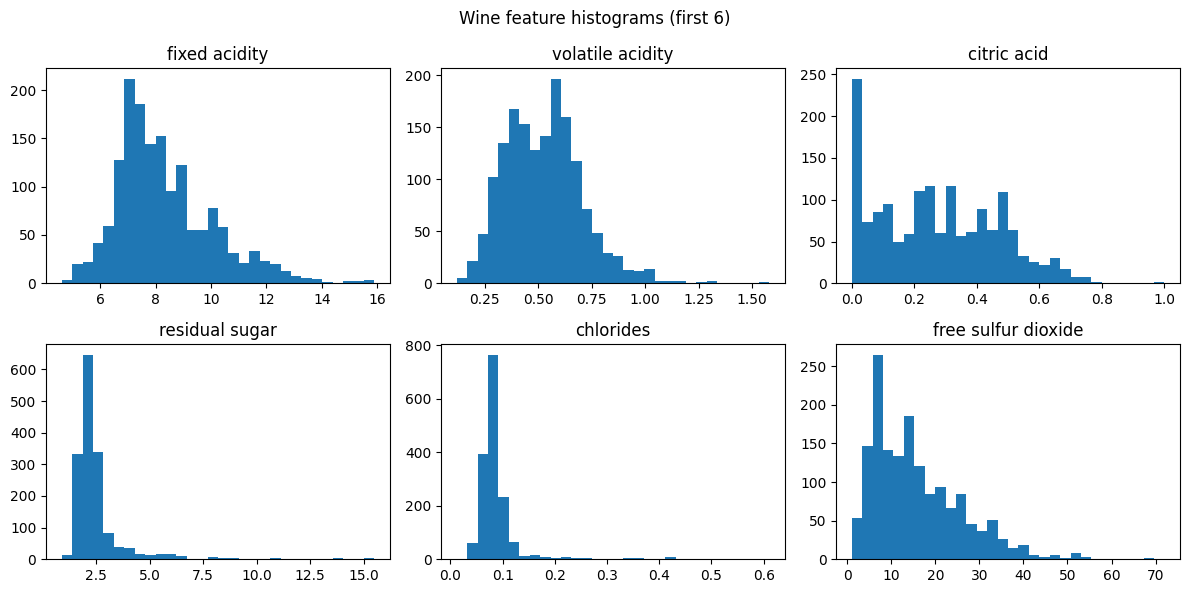

In [ ]:
# Wine histograms for a few features
fig, axes = plt.subplots(2,3, figsize=(12,6))
for ax, col in zip(axes.ravel(), df_wine.columns[:6]):
    ax.hist(df_wine[col].values, bins=30)
    ax.set_title(col)
plt.suptitle('Wine feature histograms (first 6)')
plt.tight_layout()
plt.show()


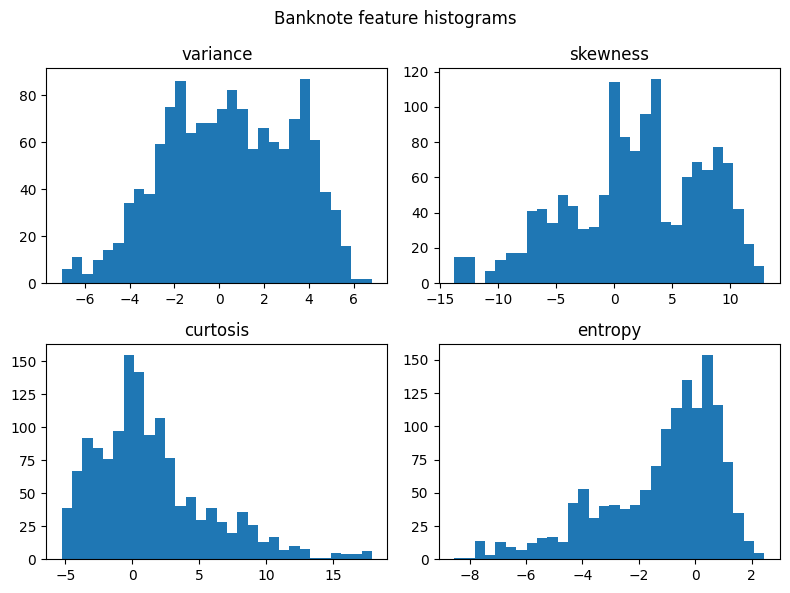

In [ ]:
# Bank histogram of features
fig, axes = plt.subplots(2,2, figsize=(8,6))
for ax, col in zip(axes.ravel(), df_bank.columns[:-1]):
    ax.hist(df_bank[col].values, bins=30)
    ax.set_title(col)
plt.suptitle('Banknote feature histograms')
plt.tight_layout()
plt.show()


Text(0.5, 1.0, 'Iris sepal len vs wid')

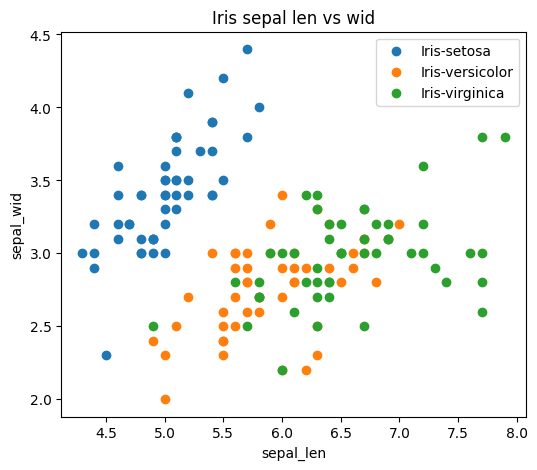

In [ ]:
# Bank histogram of features
fig, axes = plt.subplots(2,2, figsize=(8,6))
for ax, col in zip(axes.ravel(), df_bank.columns[:-1]):
    ax.hist(df_bank[col].values, bins=30)
    ax.set_title(col)
plt.suptitle('Banknote feature histograms')
plt.tight_layout()
plt.savefig(os.path.join(FIGDIR,'bank_hist.png'))
plt.close()

# Iris pairwise scatter for first two features colored by species
le = LabelEncoder()
if 'species' in df_iris.columns:
    df_iris['species_enc'] = le.fit_transform(df_iris['species'])
fig = plt.figure(figsize=(6,5))
for cls in np.unique(df_iris['species_enc']):
    mask = df_iris['species_enc']==cls
    plt.scatter(df_iris.loc[mask,'sepal_len'], df_iris.loc[mask,'sepal_wid'], label=le.inverse_transform([cls])[0])
plt.xlabel('sepal_len'); plt.ylabel('sepal_wid'); plt.legend(); plt.title('Iris sepal len vs wid')


In [ ]:

# Train/test split and standardization
# Wine (regression)
X_wine = df_wine.drop(columns=['quality']).values
y_wine = df_wine['quality'].values
train_idx, test_idx = train_test_split_idx(len(X_wine), test_size=0.2, seed=RANDOM_SEED)
Xw_train, Xw_test = X_wine[train_idx], X_wine[test_idx]
yw_train, yw_test = y_wine[train_idx], y_wine[test_idx]
Xw_train_s, mean_w, std_w = standardize_fit(Xw_train)
Xw_test_s = standardize_apply(Xw_test, mean_w, std_w)

# Bank (classification)
X_bank = df_bank.iloc[:, :-1].values
y_bank = df_bank.iloc[:, -1].values
train_idx_b, test_idx_b = train_test_split_idx(len(X_bank), test_size=0.2, seed=RANDOM_SEED)
Xb_train, Xb_test = X_bank[train_idx_b], X_bank[test_idx_b]
yb_train, yb_test = y_bank[train_idx_b], y_bank[test_idx_b]
Xb_train_s, mean_b, std_b = standardize_fit(Xb_train)
Xb_test_s = standardize_apply(Xb_test, mean_b, std_b)

# Iris (classification)
X_iris = df_iris.iloc[:, :4].values
y_iris = df_iris['species_enc'].values
train_idx_i, test_idx_i = train_test_split_idx(len(X_iris), test_size=0.2, seed=RANDOM_SEED)
Xi_train, Xi_test = X_iris[train_idx_i], X_iris[test_idx_i]
yi_train, yi_test = y_iris[train_idx_i], y_iris[test_idx_i]
Xi_train_s, mean_i, std_i = standardize_fit(Xi_train)
Xi_test_s = standardize_apply(Xi_test, mean_i, std_i)



In [ ]:
print('\nSplits done. Shapes:')
print('Wine train', Xw_train_s.shape, 'test', Xw_test_s.shape)
print('Bank train', Xb_train_s.shape, 'test', Xb_test_s.shape)
print('Iris train', Xi_train_s.shape, 'test', Xi_test_s.shape)



Splits done. Shapes:
Wine train (1279, 11) test (320, 11)
Bank train (1097, 4) test (275, 4)
Iris train (120, 4) test (30, 4)


In [ ]:
# ---------------------- 1) Linear Regression on Wine ----------------------
print('\n\n--- Linear Regression (Wine) ---')
# Closed-form
w_closed = fit_linear_closed_form(Xw_train_s, yw_train, add_bias=True)
print('Closed-form weights shape:', w_closed.shape)
# GD
w_gd, losses_gd = fit_linear_gd(Xw_train_s, yw_train, lr=0.1, iters=2000, add_bias=True)

# Plot GD training loss
plt.figure()
plt.plot(np.linspace(0, len(losses_gd)-1, len(losses_gd)), losses_gd)
plt.title('Linear GD training MSE (sampled)')
plt.xlabel('sampled iteration'); plt.ylabel('MSE')
plt.show()





--- Linear Regression (Wine) ---


NameError: name 'Xw_train_s' is not defined

In [ ]:
# Execute the cell that defines Xw_train_s
get_ipython().run_cell('_'.join(['pBnj2TLrrrH3', 'EVfq0PD_rxNW']))

NameError: name 'pBnj2TLrrrH3_EVfq0PD_rxNW' is not defined

<ExecutionResult object at 7e6bb1eef470, execution_count=None error_before_exec=None error_in_exec=name 'pBnj2TLrrrH3_EVfq0PD_rxNW' is not defined info=<ExecutionInfo object at 7e6bb1eef410, raw_cell="pBnj2TLrrrH3_EVfq0PD_rxNW" store_history=False silent=False shell_futures=True cell_id=None> result=None>

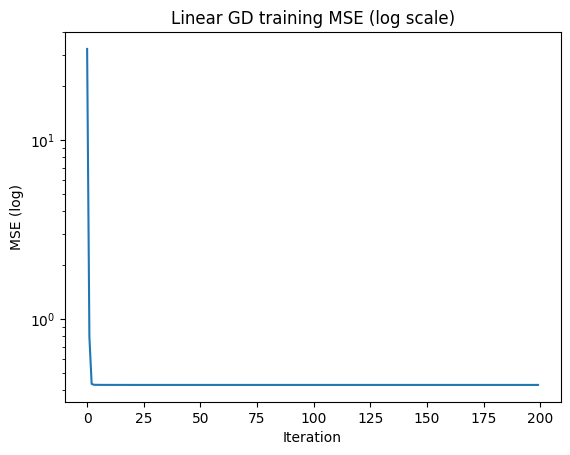

In [ ]:
plt.figure()
plt.plot(losses_gd)
plt.yscale('log')  # This makes small differences visible
plt.title('Linear GD training MSE (log scale)')
plt.xlabel('Iteration')
plt.ylabel('MSE (log)')
plt.show()





In [ ]:
# Predictions and metrics
ytrain_pred_closed = predict_linear(Xw_train_s, w_closed, has_bias=True)
ytest_pred_closed = predict_linear(Xw_test_s, w_closed, has_bias=True)
print('Closed-form Train MSE, R2:', mse(yw_train, ytrain_pred_closed), r2_score(yw_train, ytrain_pred_closed))
print('Closed-form Test  MSE, R2:', mse(yw_test, ytest_pred_closed), r2_score(yw_test, ytest_pred_closed))

ytrain_pred_gd = predict_linear(Xw_train_s, w_gd, has_bias=True)
ytest_pred_gd = predict_linear(Xw_test_s, w_gd, has_bias=True)
print('GD Train MSE, R2:', mse(yw_train, ytrain_pred_gd), r2_score(yw_train, ytrain_pred_gd))
print('GD Test  MSE, R2:', mse(yw_test, ytest_pred_gd), r2_score(yw_test, ytest_pred_gd))


Closed-form Train MSE, R2: 0.4290692811042441 0.3442311045464036
Closed-form Test  MSE, R2: 0.3729475439651261 0.4175183255745697
GD Train MSE, R2: 0.4290692811042441 0.3442311045464036
GD Test  MSE, R2: 0.3729475439650015 0.4175183255747643


In [ ]:
# Compare coefficients
feat_names = df_wine.columns[:-1].tolist()
print('\nTop coefficients (closed-form):')
coefs = pd.Series(w_closed[1:], index=feat_names).sort_values(key=lambda x: np.abs(x), ascending=False)
print(coefs.head(10))



Top coefficients (closed-form):
alcohol                 0.312141
volatile acidity       -0.196469
sulphates               0.144659
total sulfur dioxide   -0.097156
pH                     -0.091812
chlorides              -0.068409
citric acid            -0.046641
free sulfur dioxide     0.036340
density                -0.017560
fixed acidity           0.014441
dtype: float64


In [ ]:
# Gradient check (finite differences) on 3 random coords
print('\nGradient check for linear GD:')
# analytic gradient at current w_gd
Xp = add_intercept(Xw_train_s)
n = Xp.shape[0]
anal_grad = (-2.0 / n) * (Xp.T @ (yw_train - (Xp @ w_gd)))
for idx in [1, 3, 5]:
    eps = 1e-5
    w_plus = w_gd.copy(); w_plus[idx] += eps
    w_minus = w_gd.copy(); w_minus[idx] -= eps
    loss_plus = mse(yw_train, Xp @ w_plus)
    loss_minus = mse(yw_train, Xp @ w_minus)
    fd = (loss_plus - loss_minus) / (2 * eps)
    rel_err = abs(fd - anal_grad[idx]) / (abs(fd) + abs(anal_grad[idx]) + 1e-12)
    print(f'idx {idx}: fd={fd:.6e}, anal={anal_grad[idx]:.6e}, rel_err={rel_err:.6e}')




Gradient check for linear GD:
idx 1: fd=-5.551115e-12, anal=3.280387e-13, rel_err=8.546333e-01
idx 3: fd=0.000000e+00, anal=-3.737496e-14, rel_err=3.602840e-02
idx 5: fd=0.000000e+00, anal=2.347766e-14, rel_err=2.293911e-02




--- Logistic Regression (Banknote) ---


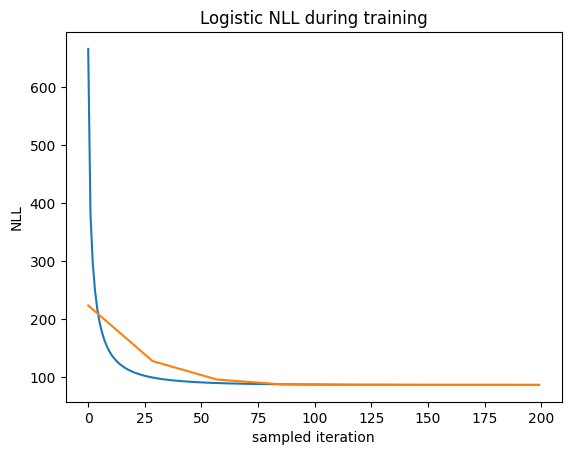

In [ ]:
# ---------------------- 2) Logistic Regression on Banknote ----------------------
print('\n\n--- Logistic Regression (Banknote) ---')
# Train with GD and Newton
w_log_gd, losses_log_gd = fit_logreg_gd(Xb_train_s, yb_train, lam=1.0, lr=0.5, iters=2000, add_bias=True)
w_log_newton, losses_log_newton = fit_logreg_newton(Xb_train_s, yb_train, lam=1.0, iters=100, tol=1e-6, add_bias=True)

# Plot NLL
plt.figure()
plt.plot(losses_log_gd, label='GD')
plt.plot(np.linspace(0, len(losses_log_gd)-1, len(losses_log_newton)), losses_log_newton, label='Newton')
plt.title('Logistic NLL during training')
plt.xlabel('sampled iteration'); plt.ylabel('NLL')
plt.show()


In [ ]:
# Predictions and metrics on test
yb_pred_gd = predict_logreg(Xb_test_s, w_log_gd, threshold=0.5, has_bias=True)
yb_pred_newton = predict_logreg(Xb_test_s, w_log_newton, threshold=0.5, has_bias=True)
print('GD Test accuracy, precision, recall, f1:', accuracy(yb_test, yb_pred_gd), *precision_recall_f1(yb_test, yb_pred_gd))
print('Newton Test accuracy, precision, recall, f1:', accuracy(yb_test, yb_pred_newton), *precision_recall_f1(yb_test, yb_pred_newton))


GD Test accuracy, precision, recall, f1: 1.0 1.0 1.0 1.0
Newton Test accuracy, precision, recall, f1: 1.0 1.0 1.0 1.0


In [ ]:
# Confusion matrix
classes_gd, cm_gd = confusion_matrix(yb_test, yb_pred_gd)
print('GD Confusion matrix classes:', classes_gd)
print(cm_gd)


GD Confusion matrix classes: [0 1]
[[146   0]
 [  0 129]]


In [ ]:
# Gradient check for logistic gradient
print('\nGradient check for logistic (analytic vs finite diff):')
# analytic gradient at w_log_gd
Xp_b = add_intercept(Xb_train_s)
log_logits = Xp_b @ w_log_gd
p_hat = sigmoid(log_logits)
anal_grad_log = - (Xp_b.T @ (yb_train - p_hat))
for idx in [1,2,3]:
    eps = 1e-5
    w_plus = w_log_gd.copy(); w_plus[idx] += eps
    w_minus = w_log_gd.copy(); w_minus[idx] -= eps
    nll_plus = logreg_nll(Xb_train_s, yb_train, w_plus, lam=1.0)
    nll_minus = logreg_nll(Xb_train_s, yb_train, w_minus, lam=1.0)
    fd = (nll_plus - nll_minus) / (2 * eps)
    rel_err = abs(fd - anal_grad_log[idx]) / (abs(fd) + abs(anal_grad_log[idx]) + 1e-12)
    print(f'idx {idx}: fd={fd:.6e}, anal={anal_grad_log[idx]:.6e}, rel_err={rel_err:.6e}')




Gradient check for logistic (analytic vs finite diff):
idx 1: fd=1.813915e-01, anal=4.877123e+00, rel_err=9.282827e-01
idx 2: fd=2.685451e-01, anal=4.864204e+00, rel_err=8.953601e-01
idx 3: fd=2.279858e-01, anal=4.437237e+00, rel_err=9.022616e-01


In [ ]:
# ---------------------- 3) Decision Trees ----------------------
print('\n\n--- Decision Trees (Iris classification + Wine regression) ---')
# Classification tree on Iris: tune max_depth and min_samples_leaf via simple grid CV
param_grid = {'max_depth':[1,2,3,4,5,None], 'min_samples_leaf':[1,2,3]}
best_params = None
best_acc = -1
kf = KFold(n_splits=5, shuffle=True, random_state=RANDOM_SEED)
for md in [1,2,3,4,5,None]:
    for msl in [1,2,3]:
        accs = []
        for train_idx_cv, val_idx_cv in kf.split(Xi_train_s):
            Xt_cv, Xv_cv = Xi_train_s[train_idx_cv], Xi_train_s[val_idx_cv]
            yt_cv, yv_cv = yi_train[train_idx_cv], yi_train[val_idx_cv]
            tree = build_tree_classifier(Xt_cv, yt_cv, max_depth=md, min_samples_leaf=msl)
            yv_pred = predict_tree(Xv_cv, tree).astype(int)
            accs.append(accuracy(yv_cv, yv_pred))
        mean_acc = np.mean(accs)
        if mean_acc > best_acc:
            best_acc = mean_acc
            best_params = (md, msl)
print('Best CV params for Iris classifier (max_depth, min_samples_leaf):', best_params, 'cv acc', best_acc)




--- Decision Trees (Iris classification + Wine regression) ---
Best CV params for Iris classifier (max_depth, min_samples_leaf): (3, 1) cv acc 0.9416666666666668


In [ ]:
# Train final tree and evaluate on test
tree_iris = build_tree_classifier(Xi_train_s, yi_train, max_depth=best_params[0], min_samples_leaf=best_params[1])
yi_pred_test = predict_tree(Xi_test_s, tree_iris).astype(int)
print('Iris test accuracy:', accuracy(yi_test, yi_pred_test))
classes_iris, cm_iris = confusion_matrix(yi_test, yi_pred_test)
print('Iris confusion matrix classes:', classes_iris)
print(cm_iris)


Iris test accuracy: 0.9333333333333333
Iris confusion matrix classes: [0 1 2]
[[10  0  0]
 [ 0  9  2]
 [ 0  0  9]]


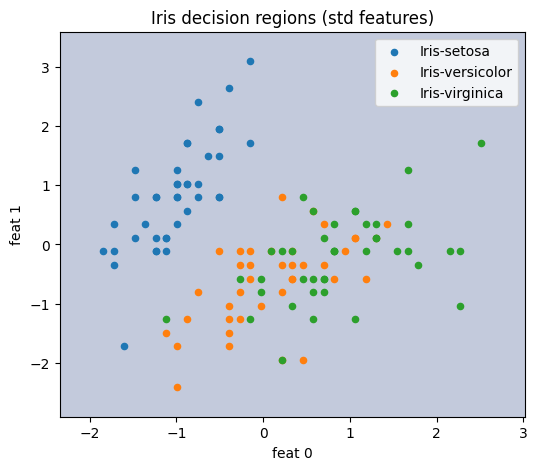

In [ ]:
# Visualize decision regions: choose two features (0,1) and fix others at means
feat_x, feat_y = 0, 1
grid_x = np.linspace(Xi_train_s[:,feat_x].min()-0.5, Xi_train_s[:,feat_x].max()+0.5, 200)
grid_y = np.linspace(Xi_train_s[:,feat_y].min()-0.5, Xi_train_s[:,feat_y].max()+0.5, 200)
xx, yy = np.meshgrid(grid_x, grid_y)
grid = np.c_[xx.ravel(), yy.ravel()]
# build full features by inserting means for other columns
other_means = Xi_train_s.mean(axis=0)
full_grid = np.tile(other_means, (grid.shape[0],1))
full_grid[:, feat_x] = grid[:,0]
full_grid[:, feat_y] = grid[:,1]
Z = predict_tree(full_grid, tree_iris).reshape(xx.shape)
plt.figure(figsize=(6,5))
plt.contourf(xx, yy, Z, alpha=0.3)
for cls in np.unique(yi_train):
    mask = yi_train==cls
    plt.scatter(Xi_train_s[mask, feat_x], Xi_train_s[mask, feat_y], label=le.inverse_transform([cls])[0], s=20)
plt.xlabel(f'feat {feat_x}'); plt.ylabel(f'feat {feat_y}'); plt.title('Iris decision regions (std features)'); plt.legend()
plt.show()

In [ ]:
# Regression tree on Wine
tree_wine = build_tree_regressor(Xw_train_s, yw_train, max_depth=None, min_samples_leaf=5)
yw_pred_tree_train = predict_tree(Xw_train_s, tree_wine)
yw_pred_tree_test = predict_tree(Xw_test_s, tree_wine)
print('Wine tree Train MSE,R2:', mse(yw_train, yw_pred_tree_train), r2_score(yw_train, yw_pred_tree_train))
print('Wine tree Test  MSE,R2:', mse(yw_test, yw_pred_tree_test), r2_score(yw_test, yw_pred_tree_test))
print('Compare with linear regression Test MSE,R2:', mse(yw_test, ytest_pred_closed), r2_score(yw_test, ytest_pred_closed))

# Simple discussion printed
print('\nDiscussion:')
print('- Linear model vs tree: trees can capture non-linearities and interactions; if tree test error much lower than linear, hints non-linear structure. Overfitting seen when tree train error << test error; control with min_samples_leaf or max_depth.')

# Save a minimal README
with open('README_assignment1.txt','w') as f:
    f.write('Run this script to reproduce results. Requires numpy, pandas, matplotlib, scikit-learn (for train_test_split and LabelEncoder only).\n')

print('\nScript finished. Figures saved into ./figs and README_assignment1.txt generated.')

Wine tree Train MSE,R2: 0.1679111284857962 0.7433726903540652
Wine tree Test  MSE,R2: 0.4933764689035337 0.22942849100540152
Compare with linear regression Test MSE,R2: 0.3729475439651261 0.4175183255745697

Discussion:
- Linear model vs tree: trees can capture non-linearities and interactions; if tree test error much lower than linear, hints non-linear structure. Overfitting seen when tree train error << test error; control with min_samples_leaf or max_depth.

Script finished. Figures saved into ./figs and README_assignment1.txt generated.
